# Curve data and conventions

Research question: Which inputs are observed and complete?

Inputs: frozen Treasury 2024–2025 CSVs. Rates are decimals, prices per 100 face. Release 1.0.0. No live signal.

In [1]:
import sys,json
from pathlib import Path
from datetime import date
import numpy as np
R=Path.cwd()
if R.name=='notebooks':R=R.parent
sys.path.insert(0,str(R/'src'));sys.path.insert(0,str(R/'scripts'))
from curve_lab.data import load_history
from curve_lab.bonds import Bond
from curve_lab.curves import bootstrap,par_rate,TENORS,KEYS,fit_nelson_siegel
from curve_lab.risk import bond_risk,hedge,carry_bridge
from curve_lab.forecast import predict,evaluate
from review_display import table,figure
if 'display_bundle' not in globals():
    from IPython.display import display
    def display_bundle(bundle):display(bundle,raw=True)
D=json.loads((R/'artifacts/release/research.json').read_text());rows,receipts=load_history(R)
print('Run',D['run_id'],'| source through',D['as_of'],'| hypothetical bond valuations')


Run p4-662f58a64e8e | source through 2025-12-31 | hypothetical bond valuations


## Audit the annual source files

In [2]:
display_bundle(table(['Year','Rows','Source SHA-256'],[[r['year'],sum(x['date'].startswith(str(r['year'])) for x in rows),r['sha256']] for r in receipts]));assert len(rows)==499;assert len({r['date'] for r in rows})==499

Year,Rows,Source SHA-256
2024,250,6775840b76cd7fd41121f61d6f6c60184eca6b2ba49954ec7372c463cbeef34d
2025,249,cf2fa3da7f160384b63d2ead698532b1d76cd9f789ce4911e2304db85b14e6d5


## Inspect observed and derived rates

Tenor,Observed par,Model zero
0.5,0.0359,0.035581602
1,0.0348,0.034491306
2,0.0347,0.034395791
3,0.0355,0.035213811
5,0.0373,0.037084535
7,0.0394,0.039341689
10,0.0418,0.042020802
20,0.0479,0.050032614
30,0.0484,0.050078252


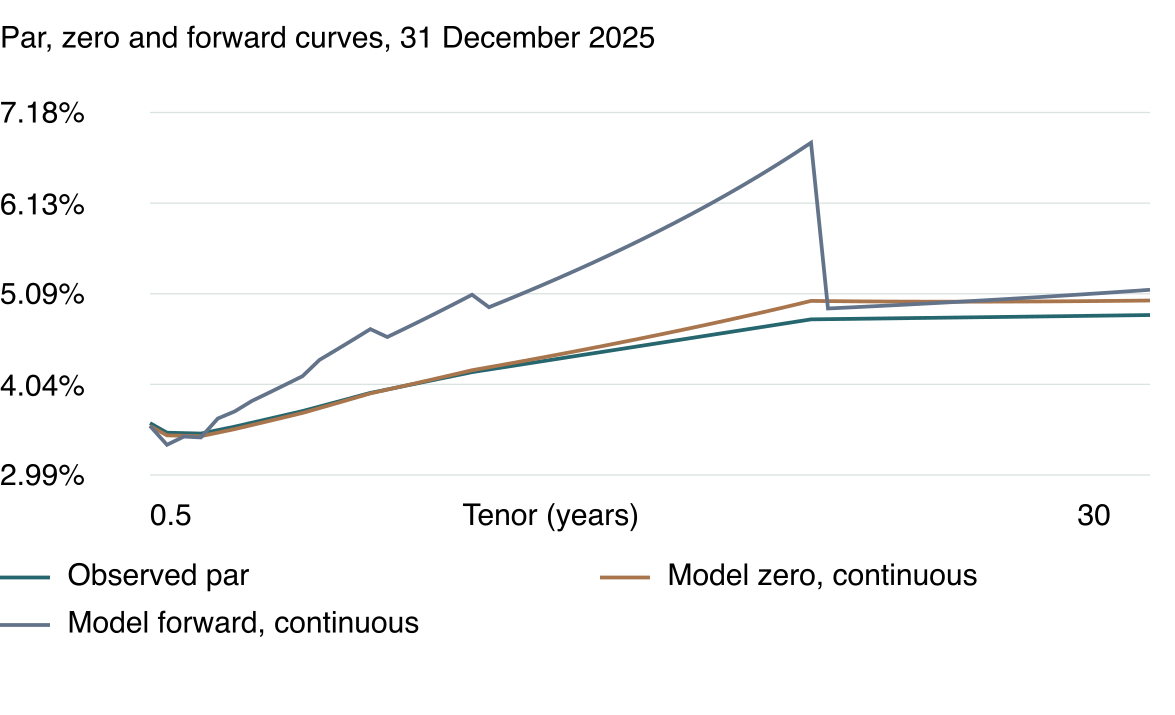

In [3]:
display_bundle(table(['Tenor','Observed par','Model zero'],zip(TENORS,rows[-1]['par'],D['history'][-1]['zero'])));display_bundle(figure('curve'))

## Make convention boundaries visible

In [4]:
display_bundle(table(['Convention','Choice'],D['config']['conventions'].items()));assert D['coverage']['missing_core']==0

Convention,Choice
coupon_accrual,Actual/Actual ICMA regular periods
curve_time,Actual/365 Fixed
payment_adjustment,Unadjusted hypothetical schedule
settlement_cashflows,Excluded; measured after same-date payment
odd_stubs,Unsupported and not represented as Treasury-compliant
reinvestment,Coupon cash earns zero


## Interpretation

The nine core tenors are complete in this snapshot. Short-tenor series outside that grid are retained raw and not imputed. Treasury par rates are observed; all discount curves and bond prices are derived. No vintage archive is available.

Canonical evidence: `artifacts/release/research.json`; source receipts: `data/manifests/sources.json`.